In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, matthews_corrcoef,
    confusion_matrix, roc_curve, precision_recall_curve
)

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'
print("Support Vector Machine and visualization packages loaded.")

Support Vector Machine and visualization packages loaded.


In [2]:
csv_path = "womens_clothing_classification_dataset.csv"
if not os.path.exists(csv_path):
    csv_path = os.path.join("27-10-2026", "Task 3", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(csv_path)
print(f"Loaded dataset: {df.shape[0]} rows, {df.shape[1]} columns")

num_features = [
    'Age', 'Rating', 'Positive Feedback Count', 'Review_Length',
    'Review_Word_Count', 'Exclamation_Count', 'Sentiment_Compound',
    'Sentiment_Pos', 'Sentiment_Neg', 'Positive_Word_Count',
    'Negative_Word_Count', 'Fit_Issue_Word_Count', 'Rating_x_Sentiment'
]
cat_features = ['Department Name', 'Division Name']
target = 'Recommended IND'

X = df[num_features + cat_features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_features)
    ]
)

X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

# Draw representative stratified calibration sample for SVM training
sample_n = 4000
train_sub_idx = np.random.RandomState(42).choice(
    X_train_trans.shape[0], size=sample_n, replace=False
)
X_sub = X_train_trans[train_sub_idx]
y_sub = y_train.iloc[train_sub_idx].values

print(f"Calibration train sample: {sample_n} observations | Held-out test set: {X_test_trans.shape[0]} observations.")

Loaded dataset: 23486 rows, 23 columns
Calibration train sample: 4000 observations | Held-out test set: 4698 observations.


In [3]:
kernel_configs = {
    'Linear Kernel (C=1.0)': SVC(kernel='linear', C=1.0, probability=True, random_state=42),
    'Polynomial Kernel (d=2, C=1.0)': SVC(kernel='poly', degree=2, C=1.0, probability=True, random_state=42),
    'Polynomial Kernel (d=3, C=1.0)': SVC(kernel='poly', degree=3, C=1.0, probability=True, random_state=42),
    'RBF Kernel (gamma=scale, C=1.0)': SVC(kernel='rbf', gamma='scale', C=1.0, probability=True, random_state=42)
}

kernel_benchmark = []
fitted_models = {}

for name, model in kernel_configs.items():
    t0 = time.time()
    model.fit(X_sub, y_sub)
    fit_time = time.time() - t0
    fitted_models[name] = model
    
    preds = model.predict(X_test_trans)
    probs = model.predict_proba(X_test_trans)[:, 1]
    
    kernel_benchmark.append({
        'Kernel_Model': name,
        'Training_Time_s': round(fit_time, 2),
        'Num_Support_Vectors': len(model.support_),
        'Pct_Support_Vectors': round((len(model.support_) / sample_n) * 100, 2),
        'Test_Accuracy': round(accuracy_score(y_test, preds), 4),
        'Test_Recall_Class0': round(recall_score(y_test, preds, pos_label=0), 4),
        'Test_Precision_Class0': round(precision_score(y_test, preds, pos_label=0, zero_division=0), 4),
        'Test_Macro_F1': round(f1_score(y_test, preds, average='macro'), 4),
        'Test_ROC_AUC': round(roc_auc_score(y_test, probs), 4),
        'Test_MCC': round(matthews_corrcoef(y_test, preds), 4)
    })

df_bench = pd.DataFrame(kernel_benchmark)
df_bench.to_csv("svm_kernel_comparison_benchmark.csv", index=False)
df_bench

C:\Users\panch\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\panch\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\panch\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\panch\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Kernel_Model,Training_Time_s,Num_Support_Vectors,Pct_Support_Vectors,Test_Accuracy,Test_Recall_Class0,Test_Precision_Class0,Test_Macro_F1,Test_ROC_AUC,Test_MCC
0,Linear Kernel (C=1.0),0.59,564,14.10,0.9421,0.8790,0.8110,0.9041,0.9771,0.8092
1,"Polynomial Kernel (d=2, C=1.0)",0.81,659,16.48,0.9293,0.6910,0.8863,0.8673,0.9617,0.7434
2,"Polynomial Kernel (d=3, C=1.0)",0.59,687,17.18,0.9272,0.6778,0.8858,0.8624,0.9619,0.7348
3,"RBF Kernel (gamma=scale, C=1.0)",0.80,732,18.30,0.9398,0.8012,0.8511,0.8945,0.9725,0.7896


C:\Users\panch\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Best SVM Parameters: {'C': 0.1, 'kernel': 'linear'}
Best CV Macro F1: 0.8999


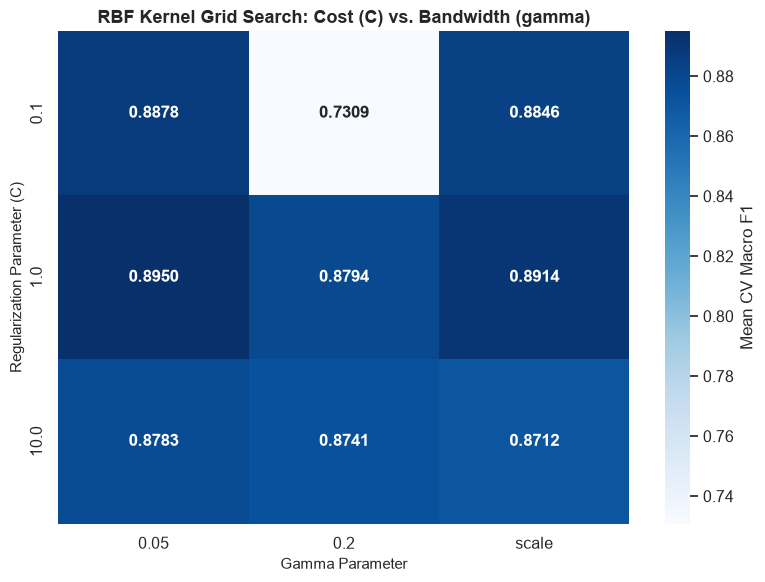

In [4]:
param_grid = [
    {
        'kernel': ['rbf'],
        'C': [0.1, 1.0, 10.0],
        'gamma': ['scale', 0.05, 0.2]
    },
    {
        'kernel': ['linear'],
        'C': [0.1, 1.0, 10.0]
    }
]

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
grid_search = GridSearchCV(
    estimator=SVC(probability=True, random_state=42),
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1
)
grid_search.fit(X_sub, y_sub)
print("Best SVM Parameters:", grid_search.best_params_)
print(f"Best CV Macro F1: {grid_search.best_score_:.4f}")

df_grid = pd.DataFrame(grid_search.cv_results_)[[
    'param_kernel', 'param_C', 'param_gamma', 'mean_test_score', 'rank_test_score', 'mean_fit_time'
]].sort_values(by='rank_test_score')
df_grid.to_csv("svm_gridsearch_tuning_results.csv", index=False)

df_rbf = df_grid[df_grid['param_kernel'] == 'rbf'].copy()
df_rbf['gamma_str'] = df_rbf['param_gamma'].astype(str)
pivot_svm = df_rbf.pivot_table(index='param_C', columns='gamma_str', values='mean_test_score')

plt.figure(figsize=(8, 6))
sns.heatmap(pivot_svm, annot=True, fmt='.4f', cmap='Blues', cbar_kws={'label': 'Mean CV Macro F1'}, annot_kws={'size': 12, 'weight': 'bold'})
plt.title("RBF Kernel Grid Search: Cost (C) vs. Bandwidth (gamma)", fontweight='bold', fontsize=13)
plt.xlabel("Gamma Parameter", fontsize=11)
plt.ylabel("Regularization Parameter (C)", fontsize=11)
plt.tight_layout()
plt.savefig("svm_hyperparameter_heatmaps.png", dpi=300)
plt.show()

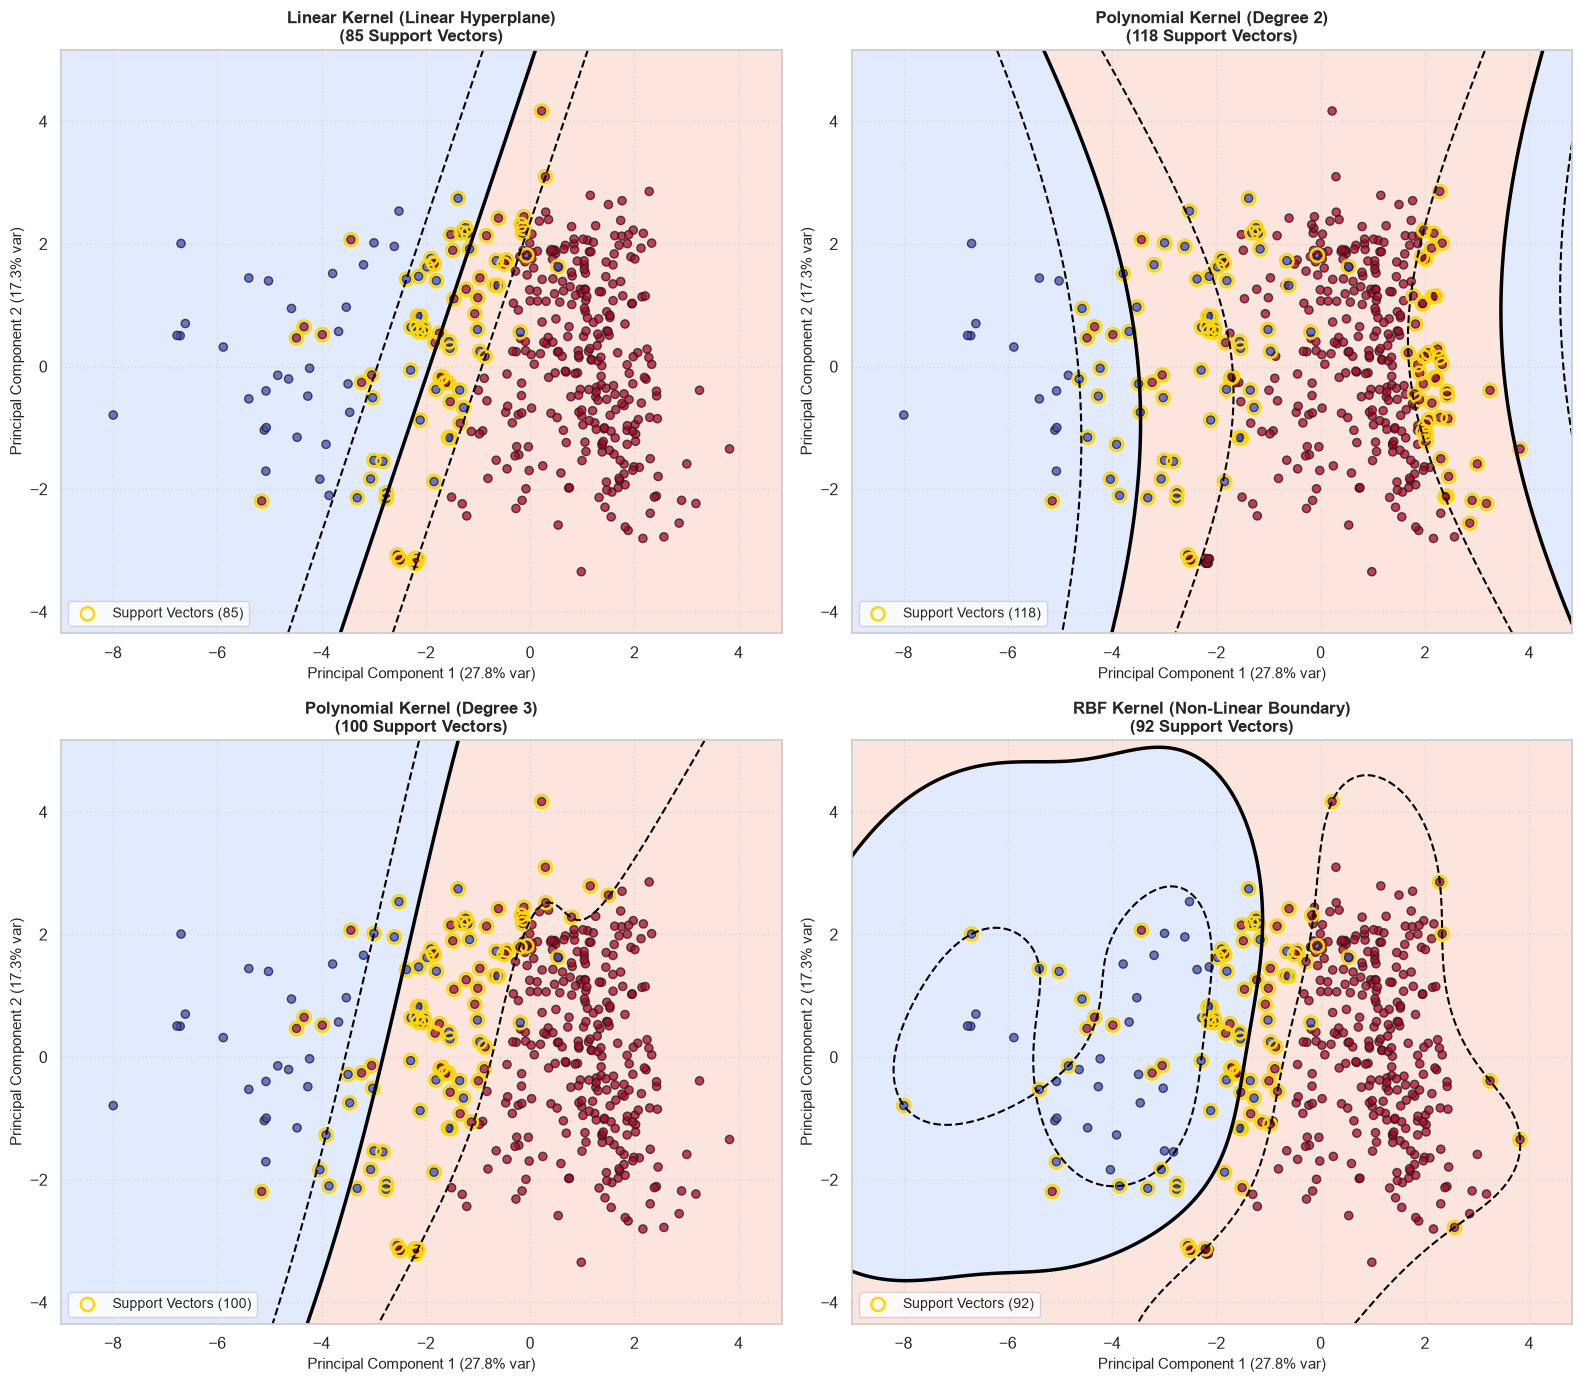

In [5]:
pca = PCA(n_components=2, random_state=42)
X_sub_pca = pca.fit_transform(X_sub)
expl_var = pca.explained_variance_ratio_

plot_idx = np.random.RandomState(42).choice(len(y_sub), size=400, replace=False)
X_plot = X_sub_pca[plot_idx]
y_plot = y_sub[plot_idx]

svm_2d_models = {
    'Linear Kernel (Linear Hyperplane)': SVC(kernel='linear', C=1.0, random_state=42),
    'Polynomial Kernel (Degree 2)': SVC(kernel='poly', degree=2, C=1.0, random_state=42),
    'Polynomial Kernel (Degree 3)': SVC(kernel='poly', degree=3, C=1.0, random_state=42),
    'RBF Kernel (Non-Linear Boundary)': SVC(kernel='rbf', gamma='scale', C=1.0, random_state=42)
}

fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.flatten()

x_min, x_max = X_plot[:, 0].min() - 1.0, X_plot[:, 0].max() + 1.0
y_min, y_max = X_plot[:, 1].min() - 1.0, X_plot[:, 1].max() + 1.0
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))

for idx, (title, clf_2d) in enumerate(svm_2d_models.items()):
    clf_2d.fit(X_plot, y_plot)
    Z = clf_2d.decision_function(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    axes[idx].contourf(xx, yy, Z > 0, alpha=0.25, cmap=plt.cm.coolwarm)
    axes[idx].contour(xx, yy, Z, levels=[-1, 0, 1], linestyles=['--', '-', '--'],
                      colors=['black', 'black', 'black'], linewidths=[1.5, 2.5, 1.5])
    
    axes[idx].scatter(
        X_plot[:, 0], X_plot[:, 1], c=y_plot, cmap=plt.cm.coolwarm,
        edgecolors='k', s=35, alpha=0.75
    )
    
    sv = clf_2d.support_vectors_
    axes[idx].scatter(
        sv[:, 0], sv[:, 1], s=90, facecolors='none', edgecolors='gold',
        linewidths=1.8, label=f'Support Vectors ({len(sv)})'
    )
    
    axes[idx].set_title(f"{title}\n({len(sv)} Support Vectors)", fontweight='bold', fontsize=12)
    axes[idx].set_xlabel(f"Principal Component 1 ({expl_var[0]*100:.1f}% var)", fontsize=11)
    axes[idx].set_ylabel(f"Principal Component 2 ({expl_var[1]*100:.1f}% var)", fontsize=11)
    axes[idx].legend(loc='lower left', frameon=True, fontsize=10)
    axes[idx].grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.savefig("svm_decision_boundaries_kernel_comparison.png", dpi=300)
plt.show()

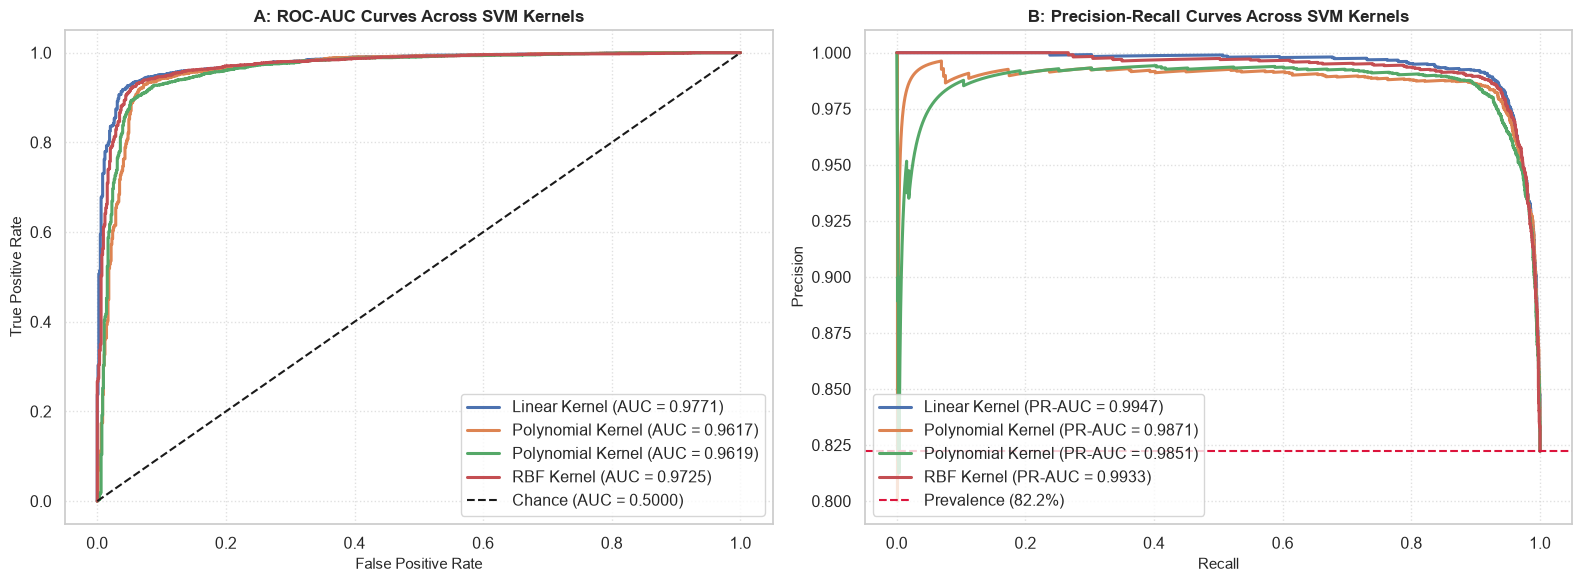

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for name, model in fitted_models.items():
    probs = model.predict_proba(X_test_trans)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    axes[0].plot(fpr, tpr, linewidth=2.2, label=f"{name.split('(')[0].strip()} (AUC = {roc_auc_score(y_test, probs):.4f})")
axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Chance (AUC = 0.5000)')
axes[0].set_title("A: ROC-AUC Curves Across SVM Kernels", fontweight='bold', fontsize=12)
axes[0].set_xlabel("False Positive Rate", fontsize=11)
axes[0].set_ylabel("True Positive Rate", fontsize=11)
axes[0].legend(loc='lower right', frameon=True)
axes[0].grid(True, linestyle=':', alpha=0.6)

for name, model in fitted_models.items():
    probs = model.predict_proba(X_test_trans)[:, 1]
    prec, rec, _ = precision_recall_curve(y_test, probs)
    axes[1].plot(rec, prec, linewidth=2.2, label=f"{name.split('(')[0].strip()} (PR-AUC = {average_precision_score(y_test, probs):.4f})")
axes[1].axhline(np.mean(y_test), color='crimson', linestyle='--', label=f'Prevalence ({np.mean(y_test)*100:.1f}%)')
axes[1].set_title("B: Precision-Recall Curves Across SVM Kernels", fontweight='bold', fontsize=12)
axes[1].set_xlabel("Recall", fontsize=11)
axes[1].set_ylabel("Precision", fontsize=11)
axes[1].legend(loc='lower left', frameon=True)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig("svm_kernel_roc_pr_curves.png", dpi=300)
plt.show()